In [169]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [1]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree
from dataclasses import asdict
import yaml
import pickle

# Local imports
from common.customTypes import DecisionType
import common.FGVizHelpers as fgtools
from params.params import Params
from multiSession.SessionManager import SessionManager

from sparcification.NFR import GraphSparsification
from rosBagRead.readFromRosbags import ReadTopicsFromRosbag
from common.groundTruthLoader import GroundTruthLoader

policy_labels = {
    "DISTANCE": "Distance",
    "OVERLAP": "Overlap",
    "INLIER_RATIO": "Inlier Ratio",
    "INLIER_RMSE": "Inlier RMSE",
    "TWO_STEP_VALIDATION": "Two Step Val",
    "TWO_OPTION": "Two Option",
    "RELATIVE_COVARIANCE": "Rel Cov"
}

policy_colors = {
    "DISTANCE": "C0",
    "OVERLAP": "C1",
    "INLIER_RATIO": "C2",
    "INLIER_RMSE": "C3",
    "TWO_STEP_VALIDATION": "C4",
    "TWO_OPTION": "C6",
    "RELATIVE_COVARIANCE": "C5"
}

figure_directory = Path("/home/benb/Pictures/ICRA_2027")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# IEEE Conference Formatting Config
# -------------------------------------------------------------------
# Single-column width = 3.5 inches; Full-width = 7.16 inches
WIDTH_SINGLE = 3.5
WIDTH_DOUBLE = 7.16

# Aspect ratio helper (e.g., 4:3 ratio -> height = width * 0.75)
HEIGHT_SINGLE = WIDTH_SINGLE * 0.75 
HEIGHT_DOUBLE = WIDTH_SINGLE * 1.00 
# For 3 stacked panels, set height proportionally (e.g., 1.1x–1.3x column width)
HEIGHT_TRIPLE = WIDTH_SINGLE * 1.25

pgf_with_rc_fonts = {
    # Match paper typography (IEEE uses Times / Times New Roman)
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    
    # Enable LaTeX math rendering
    "text.usetex": False,  # Set to True if you have full TeX distribution installed
    "pdf.fonttype": 42,    # Embed TrueType fonts so text renders as scalable vectors
    "ps.fonttype": 42,

    # Font sizes relative to IEEE standard body text (10 pt) / figure captions (8 pt)
    "font.size": 6,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "legend.fontsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,

    # Line weights and spacing
    "lines.linewidth": 1.2,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.3,
    
    # Tight margins so axes labels aren't clipped
    "figure.autolayout": True,
}

plt.rcParams.update(pgf_with_rc_fonts)

# Timing Comparison Between Dense and Approximate Marginalization

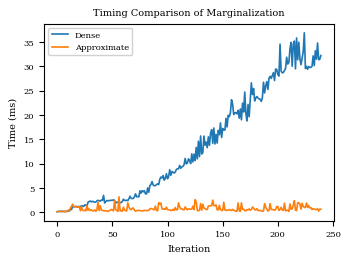

In [3]:
# Load timing pickle data and plot
timing_data_dense = np.loadtxt("../results/marginalizationEvaluation/nc/dense__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")
timing_data_approx = np.loadtxt("../results/marginalizationEvaluation/nc/approx__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")

# with open("../results/nc_tests/quad-medium_cov_current_pose_eval/update_timing_approx.pkl", "rb") as f:
#     timing_data_approx = pickle.load(f)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE))
ax.plot(timing_data_dense*1e3, label="Dense")
ax.plot(timing_data_approx*1e3, label="Approximate")
ax.set_xlabel("Iteration")
ax.set_ylabel("Time (ms)")
ax.set_title("Timing Comparison of Marginalization")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)


# Comparison of Determinants of Covariance for Dense and Approximate Marginalizations

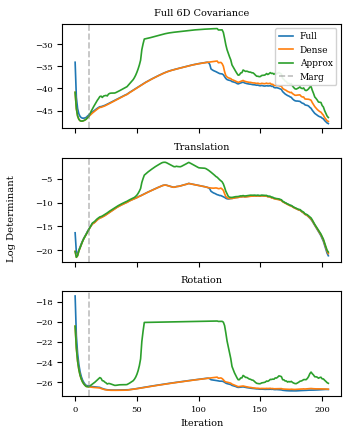

In [4]:
# Plot determinant of covariance matrices
plt.close("all")
with open("../results/marginalizationEvaluation/nc/fullSLAM__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_slam = np.asarray(pickle.load(f))

with open("../results/marginalizationEvaluation/nc/dense__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_dense = np.asarray(pickle.load(f))

with open("../results/marginalizationEvaluation/nc/approx__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_approx = np.asarray(pickle.load(f))

det_full_slam = np.linalg.det(cov_data_slam)
det_full_dense = np.linalg.det(cov_data_dense)
det_full_approx = np.linalg.det(cov_data_approx)

det_trans_slam = np.linalg.det(cov_data_slam[:, 3:, 3:])
det_trans_dense = np.linalg.det(cov_data_dense[:, 3:, 3:])
det_trans_approx = np.linalg.det(cov_data_approx[:, 3:, 3:])

det_rot_slam = np.linalg.det(cov_data_slam[:, :3, :3])
det_rot_dense = np.linalg.det(cov_data_dense[:, :3, :3])
det_rot_approx = np.linalg.det(cov_data_approx[:, :3, :3])

det_slam = np.log([det_full_slam, det_trans_slam, det_rot_slam])
det_dense = np.log([det_full_dense, det_trans_dense, det_rot_dense])
det_approx = np.log([det_full_approx, det_trans_approx, det_rot_approx])

fig, ax = plt.subplots(3, 1, figsize=(WIDTH_SINGLE, HEIGHT_TRIPLE), sharex=True)
titles = ["Full 6D Covariance", "Translation", "Rotation"]

for i in range(3):
    # ax[i].set_yscale("log")
    ax[i].plot(det_slam[i], label="Full")
    ax[i].plot(det_dense[i], label="Dense")
    ax[i].plot(det_approx[i], label="Approx")
    ax[i].axvline(11, linestyle="--", color="tab:gray", alpha=0.5, label="Marg")
    ax[i].set_title(titles[i])
    if i == 2:
        ax[i].set_xlabel("Iteration")
    # ax[i].set_ylabel("Log Det")
    if i == 0:
        ax[i].legend(loc="upper right", frameon=True, framealpha=0.9, handlelength=1.5, fontsize=6.5)

fig.supylabel("Log Determinant")
# fig.supxlabel("Iterations")

# plt.suptitle("Determinant of Covariance Matrix of\n" + rf"Current Pose ($\mathcal{{V}}_l^t$)")
plt.tight_layout()
plt.show()

In [5]:
# MUST use bbox_inches="tight" when saving, otherwise the legend off-canvas gets cropped out
plt.savefig(figure_directory / "icra_cov_eval_dense_vs_approx.pdf", format="pdf", dpi=300, bbox_inches="tight")

## Determinant Changes for Boundary Nodes

In [6]:
with open(Path("../results/transitionBoundaryEval/nc/exact/quad-hard__quad-easy/INLIER_RATIO/det_of_addToPriorNodes.pkl"), "rb") as f:
    addToPriorDets = pickle.load(f)

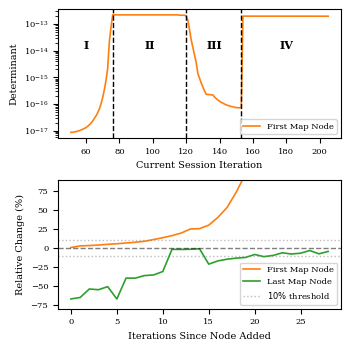

In [7]:
plt.close('Boundary Node Covariance Change Plot')
fig, ax = plt.subplots(2, 1, num='Boundary Node Covariance Change Plot', figsize=(WIDTH_SINGLE, HEIGHT_DOUBLE))
ax.flatten()
[ax1, ax2] = ax
# Determine which keys will actually be plotted
mapStartKey, mapStartDets = list(addToPriorDets.items())[0]

mapEndKey, mapEndDets = list(addToPriorDets.items())[-1]

map_start = gtsam.Symbol(mapStartKey).index()
map_end = gtsam.Symbol(mapEndKey).index()

x = np.arange(map_start, map_start+len(mapStartDets))

# Sample a continuous colormap
# colors = plt.colormaps['turbo'](np.linspace(0, 1, len(items)))
# Other nice choices: 'viridis', 'plasma', 'rainbow', 'gist_rainbow'

# for (k, dets), color in zip(items, colors):
    # ax[0].plot(dets, color=color, label=f"Key {gtsam.Symbol(k).string()}")
    # ax.plot(dets, color=color, label=f"Key {gtsam.Symbol(k).string()}")
ax1.plot(x, mapStartDets, color="C1", label=f"First Map Node")

ax1.set_yscale('log')
ax1.legend(loc="lower right")
ax1.set_xlabel("Current Session Iteration")
ax1.set_ylabel("Determinant")
# ax1.axvline(map_start, color='k', linestyle='--', linewidth=1)
ax1.axvline(76, color='k', linestyle='--', linewidth=1)
ax1.axvline(map_end, color='k', linestyle='--', linewidth=1)
ax1.axvline(153, color='k', linestyle='--', linewidth=1)

# Add roman numeral text at specified x positions
roman_labels = ['I', 'II', 'III', 'IV']
roman_x = [60, 98, 137, 180]
# Choose a reasonable y coordinate near the top of the plotting area
y_roman = np.max(mapStartDets) * 0.75  # You may adjust the multiplier if needed
y_roman = 1e-14

for rx, label in zip(roman_x, roman_labels):
    ax1.text(rx, y_roman, label, fontsize=8, ha='center', va='bottom', fontweight='bold')



duration = 30
mapStartDets = np.asarray(mapStartDets[:24])
mapEndDets = np.asarray(mapEndDets[:30])

pct_change_start = 100 * np.diff(mapStartDets) / mapStartDets[:-1]
pct_change_end = 100 * np.diff(mapEndDets) / mapEndDets[:-1]

# Determine the combined y-limits to align both y axes
combined_min = min(np.min(pct_change_start), np.min(pct_change_end))
combined_max = max(np.max(pct_change_start), np.max(pct_change_end))

# Plot start key changes
line1, = ax2.plot(pct_change_start, color="C1", label=f"First Map Node")

# Create twin y-axis for end key changes
# ax2_right = ax2.twinx()
line2, = ax2.plot(pct_change_end, color="C2", label=f"Last Map Node")

# Set same y-limits for both axes to align them
# ax2.set_ylim(combined_min, combined_max)
ax2.set_ylim(-80, 90)
# ax2_right.set_ylim(combined_min, combined_max)

# Set label colors to match plot colors
ax2.set_ylabel("Relative Change (%)")
# ax2.set_ylabel("Boundary Node Relative Change (%)", color="C1")
# ax2.right_ax = ax2_right  # Optional: keep reference
# ax2_right.set_ylabel("Boundary End Mapping Relative Change (%)", color="C2")

ax2.set_xlabel("Iterations Since Node Added")
ax2.axhline(0, linestyle='--', linewidth=1, color="k", alpha=0.5)
ax2.axhline(10, linestyle=':', linewidth=1, color="tab:gray", alpha=0.5)
line3 = ax2.axhline(-10, linestyle=':', linewidth=1, color="tab:gray", alpha=0.5, label=r"$10\%$ threshold")

# Set ticks/labels color to match plot
# ax2.tick_params(axis='y', colors="C1")
# ax2_right.tick_params(axis='y', colors="C2")

# Legends for both y axes
lines = [line1, line2, line3]
labels = [line.get_label() for line in lines]
ax2.legend(lines, labels, loc="lower right")
# ax2.grid(True)


plt.tight_layout()
plt.show()

In [8]:
plt.savefig(figure_directory / "Boundary_Node_Covariance_Change_Plot.pdf", format="pdf", dpi=300)#, bbox_inches="tight")

## Timing Plots For Each Decision Policy

RELATIVE_COVARIANCE: size = 2185, mean = 6.846 (ms), sd = 6.001
TWO_OPTION: size = 2185, mean = 479.731 (ms), sd = 792.832
TWO_STEP_VALIDATION: size = 2185, mean = 3.756 (ms), sd = 24.995
INLIER_RMSE: size = 2185, mean = 137.592 (ms), sd = 136.905
INLIER_RATIO: size = 2185, mean = 137.628 (ms), sd = 136.303
OVERLAP: size = 2185, mean = 14.227 (ms), sd = 6.801
DISTANCE: size = 2185, mean = 0.843 (ms), sd = 0.418
Skipping None


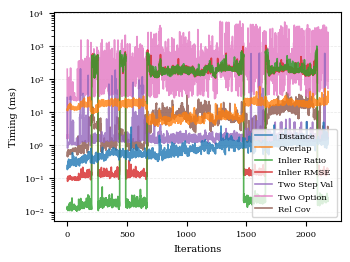

In [9]:
mainDir = Path("/home/benb/blocklio/python/results/accuracyEval/nc/exact/post/park__cloister__quad-hard__quad-medium__quad-easy")

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
# plt.figure(figName)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE), num=figName)
lines = []
for dt in reversed(DecisionType):
    if dt == DecisionType.NONE:
        print("Skipping None")
        continue
    tmpPath = mainDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    if not tmpPath.is_file():
        print(f"Not a file: {str(tmpPath)}")
        continue

    timing_data[dt.name] = np.loadtxt(tmpPath)
    print(f"{dt.name}: size = {timing_data[dt.name].size}, mean = {np.mean(timing_data[dt.name])*1e3:.3f} (ms), sd = {np.std(timing_data[dt.name]*1e3):.3f}")
    lines += ax.plot(timing_data[dt.name] * 1e3, label=policy_labels[dt.name], color=policy_colors[dt.name], alpha=0.8)


# twoOptionFile = Path("/home/benb/blocklio/python/results/accuracyEval/nc/exact/post2option/park__cloister__quad-hard__quad_medium__quad-easy/TWO_STEP_VALIDATION/timeToCalcMetricsAndDecision.txt")
# twoOptionData = np.loadtxt(twoOptionFile)
# lines += ax.plot(twoOptionData * 1e3, label="Two Option", alpha=0.8)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
# plt.title("Decision Policy Timing Comparison")
# lines.reverse()
# labels = [line.get_label() for line in lines]
# plt.legend(lines, labels, loc="lower right",)
plt.legend(loc="lower right", reverse=True)

# plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')




In [183]:
plt.savefig(figure_directory / "Policy_Timing_Comparison.pdf", format="pdf", dpi=300)#, bbox_inches="tight")